# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs [""]
    -- level2/raytracing [""]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = "raytracing"
    build_script = True  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpt4o"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "04test_o1p_ee_altis-rayt"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: raytracing/raytracing_cuda

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpt4o
System Prompt Index: CUDA
Code file template: generated_codes/altis/src/cuda/level2/raytracing/raytracing_cuda/raytracing

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and analysis of the source code's functions, classes, and

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: /home/cc/lassi/LASSI_dev/source_codes/altis/build/bin/level2
Execute command: ['./raytracing']

Chose device: name='Tesla P100-PCIE-16GB' index=0

test                               atts                                  units       median         mean           stddev         min            max            
raytracingrenderingtime            img:400by300,samples:10,iter:10       sec         0.636174       0.639958       0.00772458     0.631914       0.65839        
raytracingtotalexecutiontime       img:400by300,samples:10,iter:10       sec         6.46286        6.46286        0              6.46286        6.46286        

Note: results marked with (*) had missing values such as
might occur with a mixture of architectural capabilities.
GPU power data has been written to source_CUDA_gpu_power_results.csv


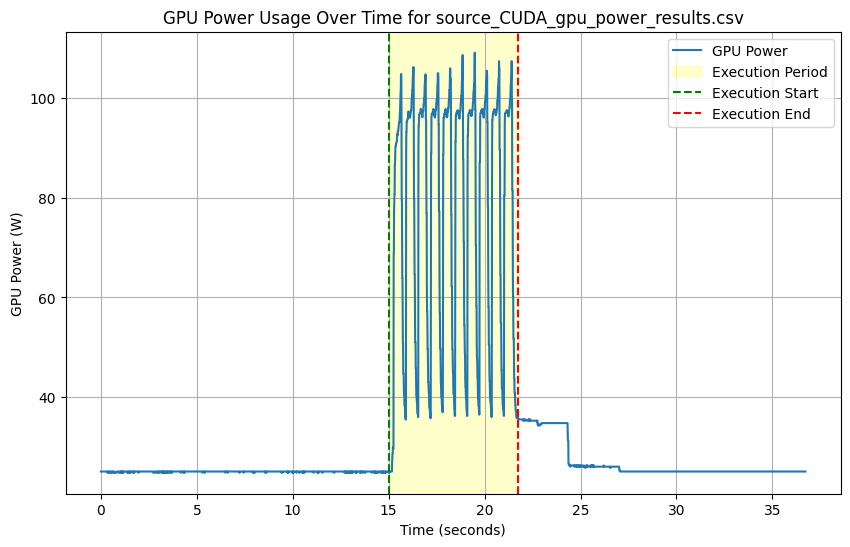

Start time: 15.001 -- End time: 21.727

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.73 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000147 kWh
  0.1471 Wh
  529.43 J
Average GPU power: 78.76 W
Total Energy During Exe Runtime:   529.43 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 6.73
GPU power data has been written to idle__gpu_power_results.csv


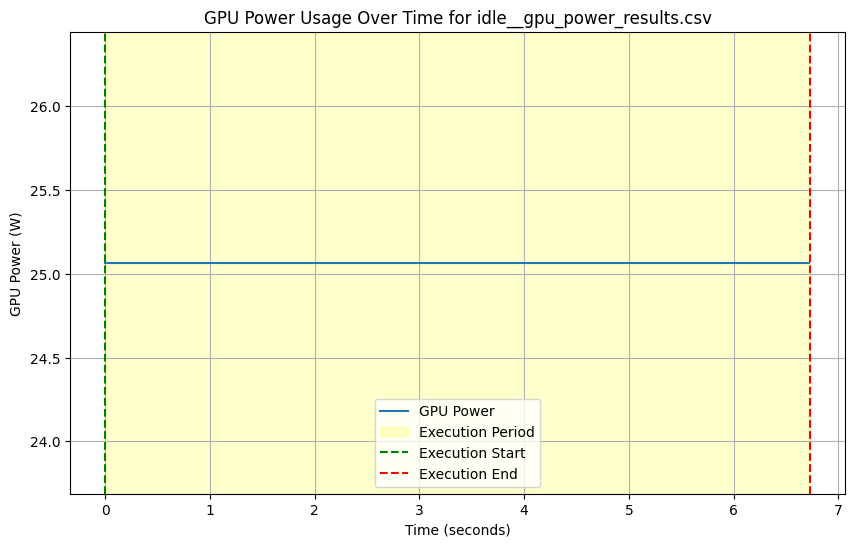

Start time: 0 -- End time: 6.727

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.73 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000047 kWh
  0.0469 Wh
  168.74 J
Average GPU power: 25.07 W
Total Energy During Exe Runtime:   168.74 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


--> ... prompt LLM to summarize context knowledge.

**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device:**
   - **Avoid Unnecessary Transfers:** Reduce the frequency and volume of data transfers between the host (CPU) and the device (GPU). Each transfer consumes energy and can become a bottleneck.
   - **Device-Resident Data Structures:** Create and manipulate intermediate data entirely 

**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device:**
   - **Avoid Unnecessary Transfers:** Reduce the frequency and volume of data transfers between the host (CPU) and the device (GPU). Each transfer consumes energy and can become a bottleneck.
   - **Device-Resident Data Structures:** Create and manipulate intermediate data entirely on the device without transferring it back to the host. Allocate, operate on, and deallocate device memory without host involvement.
   - **Batch Transfers:** When transfers are necessary, batch small transfers into larger ones to reduce overhead. This may involve packing non-contiguous memory regions into contiguous buffers.
   - **Use Page-Locked (Pinned) Memory:** Utilize pinned memory to achieve higher bandwidth during data transfers, reducing transfer time and energy consumption.

2. **Optimize Memory Access Patterns:**
   - **Prefer Shared Memory Over Global Memory:**
     - Shared memory is a low-latency memory space accessible by all threads within a thread block.
     - Utilize shared memory for data that is accessed multiple times by threads in a block to reduce global memory accesses.
     - Minimizing global memory accesses reduces latency and energy consumption.
   - **Efficient Use of Memory Spaces:**
     - Understand and leverage the memory hierarchy (registers, shared memory, global memory) for efficient data access.
     - Use distributed shared memory in Thread Block Clusters for inter-block communication when available.

3. **Avoid Warp Divergence:**
   - **Minimize Divergent Execution Paths:**
     - Structure code to ensure that all threads within a warp follow the same execution path.
     - Avoid branching based on thread-specific conditions that can cause threads within a warp to diverge.
   - **Optimize Conditional Statements:**
     - Where branching is necessary, align conditions with warp boundaries to minimize divergence.
     - Small branches may be optimized by the compiler using predication to avoid divergence.

4. **Maintain High Occupancy:**
   - **Sufficient Active Threads:**
     - Utilize enough threads per multiprocessor to keep the GPU cores busy and hide latency from memory operations and register dependencies.
     - High occupancy ensures better utilization of the GPU resources, reducing idle times and energy waste.
   - **Thread Block Size as a Multiple of Warp Size:**
     - Configure thread blocks with a size that's a multiple of 32 (the warp size).
     - This facilitates efficient execution and memory access patterns.

5. **Optimize Mathematical Computations:**
   - **Use Fast Math Libraries:**
     - Employ fast math functions (e.g., `__sinf()`, `__expf()`) when high precision is not critical.
     - Fast math functions execute more quickly and consume less energy.
     - Be cautious of reduced precision and altered special case handling.
   - **Prefer Specialized Functions Over General Ones:**
     - Use functions like `exp2()`, `exp10()`, `cbrt()` instead of general `pow()` functions when applicable.
     - Replace `sin(π * x)` with `sinpi(x)` for both performance and accuracy benefits.
   - **Explicit Multiplication for Small Powers:**
     - Calculate small integer powers by explicit multiplication (e.g., `x * x` for `x^2`) instead of using `pow()`.

6. **Efficient Arithmetic Operations:**
   - **Use Bitwise Operations:**
     - Replace expensive division and modulo operations with bitwise shifts and masks when operands are powers of two.
     - For example, use `i >> n` instead of `i / (1 << n)` and `i & (n - 1)` instead of `i % n`.
   - **Signed vs. Unsigned Integers:**
     - Use signed integers for loop counters and arithmetic operations.
     - Allows the compiler to perform more aggressive optimizations, potentially reducing execution time and energy usage.

7. **Reduce Instruction Overhead:**
   - **Avoid Unnecessary Type Conversions:**
     - Prevent implicit type conversions between doubles and floats, which can introduce additional instructions and energy consumption.
     - Use single-precision constants (e.g., `1.0f` instead of `1.0`) when working with `float` types.
   - **Leverage Compiler Optimizations:**
     - Enable compiler flags and pragmas that optimize loops and unroll iterations where beneficial.
     - Example: Use `#pragma unroll` to unroll loops for better performance.

8. **Efficient Thread Synchronization:**
   - **Minimize Synchronization Overhead:**
     - Use `__syncthreads()` and other synchronization primitives judiciously.
     - Avoid unnecessary synchronizations that can cause threads to idle, wasting energy.
   - **Use Advanced Synchronization When Available:**
     - Starting with newer GPU architectures, utilize features like Independent Thread Scheduling and the Cooperative Groups API for more efficient synchronization.

9. **Utilize Appropriate Hardware Features:**
   - **Thread Block Clusters:**
     - On GPUs with compute capability 9.0 or higher, use Thread Block Clusters to enable efficient inter-block communication and synchronization.
     - Take advantage of Distributed Shared Memory for energy-efficient data sharing between blocks.
   - **Unified Memory:**
     - Consider using Unified Memory to simplify memory management and potentially reduce unnecessary data transfers.
     - Be aware of the performance characteristics and ensure it aligns with energy efficiency goals.

10. **Optimize Kernel Launch Configuration:**
    - **Grid and Block Dimensions:**
      - Choose grid and block dimensions that maximize resource utilization without exceeding hardware limitations.
      - Ensuring optimal occupancy can reduce energy consumption by keeping GPU cores active.
    - **Align Data Structures for Coalesced Access:**
      - Organize data in memory to enable coalesced memory accesses by threads within a warp.
      - Coalesced accesses reduce memory transactions and energy usage.

11. **Efficient Use of Asynchronous Operations:**
    - **Leverage Asynchronous Memory Copy:**
      - Use `cuda::memcpy_async` to overlap data transfers with computation, reducing idle times.
      - Synchronize asynchronous operations efficiently using synchronization objects like `cuda::barrier` or `cuda::pipeline`.
    - **Pipeline Execution:**
      - Implement data transfer and computation pipelines to keep GPU units busy and improve energy efficiency.

**Applying These Points in Code Refactoring:**

When refactoring code for energy efficiency, incorporate the above practices by:

- **Analyzing Data Transfer Patterns:**
  - Identify and eliminate unnecessary host-device transfers.
  - Keep data resident on the device as much as possible.

- **Optimizing Memory Usage:**
  - Refactor code to use shared memory for frequently accessed data within a block.
  - Reorganize data structures to improve memory access patterns.

- **Reducing Control Flow Divergence:**
  - Restructure conditional statements to minimize warp divergence.
  - Align thread operations to ensure uniform execution paths within warps.

- **Enhancing Mathematical Computations:**
  - Replace generic math functions with specialized or fast math functions where precision allows.
  - Simplify complex expressions to reduce computational overhead.

- **Improving Kernel Configurations:**
  - Adjust thread block sizes to optimize occupancy and performance.
  - Utilize occupancy calculators to determine the optimal configuration for the target GPU.

- **Streamlining Synchronization:**
  - Remove redundant synchronization points.
  - Utilize advanced synchronization mechanisms for better efficiency.

By carefully applying these strategies, the refactored code will not only maintain its original functionality but also operate more energy efficiently, leveraging the full potential of the CUDA platform and GPU hardware.


--> ... prompt LLM to describe the source code.

**Overview:**

The provided CUDA C++ code is an implementation of a ray tracing renderer optimized for GPU execution. It leverages CUDA to parallelize the computation-intensive tasks involved in ray tracing, such as calculating ray-object intersections, shading, and generating randomness for sampling. The code is structured to set up a scene with various objects and materials, initialize random states for Monte Carlo ray tracing, and render an image by computing the color for each pixel in parallel.

**Major Classes and Data Structures:**

1. **vec3:**
   - Represents a three-dimensional vector.
   - Used for positions, directions, colors, and calculations involving 3D coordinates.
   - Provides vector operations like addition, multiplication, dot product, and normalization.

2. **ray:**
   - Represents a ray in 3D space with an origin and a direction.
   - Used to trace the path of light through the scene.

3. **hitable (Abstract Class

**Overview:**

The provided CUDA C++ code is an implementation of a ray tracing renderer optimized for GPU execution. It leverages CUDA to parallelize the computation-intensive tasks involved in ray tracing, such as calculating ray-object intersections, shading, and generating randomness for sampling. The code is structured to set up a scene with various objects and materials, initialize random states for Monte Carlo ray tracing, and render an image by computing the color for each pixel in parallel.

**Major Classes and Data Structures:**

1. **vec3:**
   - Represents a three-dimensional vector.
   - Used for positions, directions, colors, and calculations involving 3D coordinates.
   - Provides vector operations like addition, multiplication, dot product, and normalization.

2. **ray:**
   - Represents a ray in 3D space with an origin and a direction.
   - Used to trace the path of light through the scene.

3. **hitable (Abstract Class):**
   - Defines an interface for objects that can be intersected by rays.
   - Contains a virtual function `hit` which determines if a ray hits the object.

4. **sphere (Inherits from hitable):**
   - Represents a sphere object in the scene.
   - Implements the `hit` function to calculate ray-sphere intersections.
   - Contains a pointer to a material to define surface properties.

5. **hitable_list (Inherits from hitable):**
   - Represents a collection of hitable objects.
   - Implements the `hit` function to check for intersections with any object in the list.

6. **material (Abstract Class):**
   - Defines surface interaction properties.
   - Contains a virtual function `scatter` that models how rays interact with the material.

7. **Material Subclasses:**
   - **lambertian:**
     - Represents diffuse materials that scatter light in all directions.
   - **metal:**
     - Represents metallic surfaces with reflective properties.
   - **dielectric:**
     - Represents transparent materials like glass, modeling refraction.

8. **camera:**
   - Defines the viewing parameters for the scene.
   - Contains functions to generate rays passing through pixels.

9. **hit_record:**
   - A structure used to store information about ray-object intersections.
   - Contains details like the point of intersection, normal at that point, and material pointer.

10. **curandState:**
    - CUDA's random number generator state.
    - Used for generating random numbers in device code for Monte Carlo sampling.

**Major Functions and Kernels:**

1. **`__device__ vec3 color(const ray& r, hitable **world, curandState *local_rand_state)`:**
   - Computes the color seen by a ray as it interacts with the scene.
   - Uses a loop to limit recursion depth (up to 50 iterations) to prevent stack overflow on the GPU.
   - At each interaction, it checks for ray-object intersections.
     - If it hits an object, it calculates the attenuation and generates a scattered ray based on the material properties.
     - If it doesn't hit any object, it computes a background color based on the ray's direction.
   - Accumulates the color contribution at each interaction.

2. **`__global__ void rand_init(curandState *rand_state)`:**
   - Initializes the random number generator state for the entire scene creation.
   - Only executed by a single thread (thread 0 in block 0).

3. **`__global__ void render_init(int max_x, int max_y, curandState *rand_state)`:**
   - Initializes the random number generator state for each pixel in the image.
   - Each thread corresponds to a pixel and seeds its own `curandState` using a unique sequence number.

4. **`__global__ void render(vec3 *fb, int max_x, int max_y, int ns, camera **cam, hitable **world, curandState *rand_state)`:**
   - The main rendering kernel.
   - Each thread computes the color for a single pixel.
   - Performs multiple samples per pixel (`ns` times) to implement anti-aliasing and improve image quality.
     - Generates random offsets within the pixel for supersampling.
     - Traces rays through the scene using the `color` function.
     - Averages the color contributions from all samples.
   - Applies gamma correction (square root) to the color before storing it in the framebuffer.

5. **`__global__ void create_world(hitable **d_list, hitable **d_world, camera **d_camera, int nx, int ny, curandState *rand_state)`:**
   - Constructs the scene by creating various spheres with different materials.
     - Includes a large ground sphere and many small spheres randomly placed in the scene.
     - Randomly assigns materials to the small spheres (diffuse, metal, or dielectric).
   - Initializes the camera with given parameters.
   - Only executed by a single thread to prevent race conditions during object creation.

6. **`__global__ void free_world(hitable **d_list, hitable **d_world, camera **d_camera)`:**
   - Frees the dynamically allocated memory for the objects and materials in the scene.
   - Cleans up resources to prevent memory leaks.

7. **`void addBenchmarkSpecOptions(OptionParser &op)`:**
   - Adds command-line options for customizing the benchmark execution.
     - Options include image dimensions (`X`, `Y`) and the number of samples per pixel.

8. **`void RunBenchmark(ResultDatabase &DB, OptionParser &op)`:**
   - The main function orchestrating the benchmark.
   - Parses command-line options and initializes timers for performance measurement.
   - Sets up the rendering parameters and allocates memory for the framebuffer and random states.
   - Calls `create_world` to set up the scene.
   - Launches the rendering kernels (`render_init` and `render`) inside a loop to perform multiple passes.
   - Records the execution time for each pass and adds the results to the database.
   - Optionally outputs the rendered image (currently disabled with `#if 0`).
   - Calls `free_world` to clean up resources.
   - Reports total execution time and resets the CUDA device.

**Additional Details:**

- **Random Number Generation:**
  - Uses CUDA's `curand` library to generate random numbers on the device.
  - Each pixel has its own random state to ensure uncorrelated sequences.

- **Rendering Loop:**
  - The rendering is done over multiple passes (determined by the `passes` option).
  - In each pass, the image is rendered, and execution time is measured.
  - Anti-aliasing is achieved through Monte Carlo sampling within each pixel.

- **Memory Management:**
  - Uses both managed memory (`cudaMallocManaged`) and device memory (`cudaMalloc`) based on the options specified.
  - Managed memory simplifies memory management by providing a unified memory space accessible by both host and device.

- **Scene Setup:**
  - The scene consists of a grid of randomly placed spheres, simulating a complex environment.
  - Materials are assigned randomly to create diversity in surface interactions.

- **Camera Configuration:**
  - Positioned at a point in space (`lookfrom`) and aimed at a target point (`lookat`).
  - Configured with depth of field effects through aperture and focus distance.

- **Performance Measurement:**
  - Utilizes CUDA events (`cudaEvent_t`) to measure GPU execution time accurately.
  - Records both per-pass rendering time and total execution time.

- **Concurrency and Parallelism:**
  - Exploits data parallelism by mapping each pixel computation to a CUDA thread.
  - Adjusts the grid and block dimensions based on image size and tile size (configured with `tx` and `ty`).

- **Utility Functions:**
  - **`#define RND (curand_uniform(&local_rand_state))`**
    - Macro to simplify calling `curand_uniform` with the local random state.
    - Enhances code readability during scene creation.

**Summary of Functional Blocks:**

- **Initialization:**
  - Parse options and initialize random states.
  - Allocate memory for framebuffer and random number generators.

- **Scene Creation:**
  - Create objects and materials in the world.
  - Initialize the camera parameters.

- **Rendering:**
  - Initialize per-pixel random states (`render_init`).
  - Render the image by computing colors for each pixel (`render`).
    - Perform multiple samples per pixel for anti-aliasing.
    - Use Monte Carlo methods for sampling and shading.

- **Post-processing:**
  - Apply gamma correction to the final colors.
  - Optionally output the image.

- **Cleanup:**
  - Free allocated memory and resources.
  - Reset the CUDA device.

**Incorporation of Best Practices:**

- **Loop-based Recursion Limitation:**
  - Converted recursive `color` function to a loop to prevent stack overflows on the GPU.
  - Aligns with best practices by avoiding deep recursion in device code.

- **Controlled Randomness:**
  - Each thread manages its own random state to maintain statistical independence.
  - Ensures reproducibility and avoids correlation in random sequences.

- **Efficient Memory Access:**
  - Uses managed memory to simplify data transfers and memory coherence.
  - Allocates per-pixel data contiguously to enhance memory coalescing.
  - Avoids unnecessary data transfers between host and device by performing all computations on the device.

- **Occupancy Considerations:**
  - Blocks and threads are configured to ensure sufficient active threads per multiprocessor.
  - Tile size (`tx` and `ty`) is set to multiples of 8 to facilitate warp scheduling and efficiency.

- **Single-Threaded Scene Creation:**
  - Scene objects are created by a single thread to prevent race conditions.
  - Although this serializes scene setup, it is a necessary trade-off given dynamic memory allocation on the device.

**Conclusion:**

The provided CUDA C++ code efficiently implements a ray tracing renderer optimized for execution on NVIDIA GPUs. It carefully manages device resources, leverages parallelism for per-pixel computations, and applies CUDA best practices to enhance performance while maintaining correct functionality. The use of Monte Carlo sampling, diverse materials, and complex scene setups results in visually rich rendered images.



----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 14559): 


[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is specified using a new <<<. . . >>> execution configuration syntax (see C++ Language Extensions) . Each thread that executes the kern

**Summary of Identified Inefficiencies:**

1. **Inefficient Memory Usage and Data Transfers:**
   - **Dynamic Memory Allocation on Device:**
     - The `create_world` kernel performs dynamic memory allocation (`new`) within device code to create scene objects and materials. This is inefficient as dynamic allocation on the GPU can be costly and lead to fragmentation.
   - **Unified Memory Overhead:**
     - Use of `cudaMallocManaged` (Unified Memory) for allocations like the framebuffer (`fb`) and scene objects may introduce overhead due to data migration between host and device, especially if the data remains on the device.
   - **Per-Pixel Random States in Global Memory:**
     - Storing `curandState` per-pixel in global memory leads to high latency accesses during random number generation.

2. **Single-Threaded Scene Creation and Cleanup:**
   - The `create_world` and `free_world` kernels are executed by a single thread, causing scene setup and cleanup to be serialized and underutilizing the GPU's parallel capabilities.

3. **Warp Divergence and Control Flow:**
   - The `color` function contains loops and conditional branches based on per-thread data (e.g., material properties), causing warp divergence. Threads within the same warp may follow different execution paths, reducing execution efficiency.

4. **Low Occupancy Due to Small Block Size:**
   - Using a thread block size of 8x8 (64 threads per block) may not be sufficient to fully utilize GPU resources, resulting in low occupancy and inefficient execution.

5. **Inefficient Random Number Generation:**
   - Each thread initializes and uses its own `curandState`, which involves reading and writing global memory per pixel. This leads to memory latency and inefficient use of random number generators.

6. **Lack of Shared Memory Usage:**
   - The program does not utilize shared memory for caching frequently accessed data, leading to repeated global memory accesses and increased latency.

7. **Unnecessary Synchronizations:**
   - `cudaDeviceSynchronize()` is called after each kernel launch, which may be unnecessary and introduces synchronization overhead, causing threads to idle.

8. **Inefficient Mathematical Operations:**
   - Functions like `sqrt` are used without leveraging faster alternatives (e.g., `rsqrtf` or fast math intrinsics). Double-precision constants are used where single precision would suffice.

9. **Dynamic Polymorphism in Device Code:**
   - Use of virtual functions (`hit`, `scatter`) in device code introduces overhead due to dynamic dispatch and can increase register pressure, reducing performance.

10. **Non-Coalesced Memory Accesses:**
    - Access patterns to the framebuffer (`fb`) and random state arrays may not be optimized for memory coalescing, resulting in inefficient global memory accesses.

11. **Use of Unsigned Integers for Loop Counters:**
    - Using unsigned integers in loops and indices may prevent certain compiler optimizations, leading to less efficient code.

12. **Absence of Asynchronous Operations:**
    - The code does not utilize asynchronous memory operations or CUDA streams to overlap data transfers with computation, potentially causing idle GPU time.

---

**Refactoring Plan to Improve Energy Efficiency:**

1. **Parallelize Scene Creation and Cleanup:**
   - **Action:**
     - Move scene object and material allocation from device code to host code. Allocate and initialize all scene objects and materials on the host, then transfer them to the device in contiguous memory blocks.
     - Replace per-object allocations with pre-allocated arrays to hold scene data.
     - **Benefit:**
       - Eliminates dynamic memory allocation on the device, reduces overhead and fragmentation.
       - Allows for parallel data transfer optimizations, and scene creation can be fully parallelized on the host.

2. **Avoid Dynamic Memory Allocation in Device Code:**
   - **Action:**
     - Replace `new` and `delete` operations in device code with pre-allocated buffers.
     - Use arrays of structures or structure of arrays to store scene data compactly.
     - **Benefit:**
       - Reduces runtime overhead and avoids potential memory fragmentation on the device.
       - Enhances memory access efficiency by using contiguous memory regions.

3. **Increase Thread Block Size to Improve Occupancy:**
   - **Action:**
     - Increase the thread block size to 16x16 (256 threads per block) or another multiple of 32 that results in higher occupancy.
     - Adjust grid dimensions accordingly to cover the entire image.
     - **Benefit:**
       - Higher occupancy allows the GPU to better hide memory and execution latencies.
       - Improves resource utilization, leading to faster execution and reduced energy consumption.

4. **Optimize Random Number Generation:**
   - **Action:**
     - Initialize `curandState` once per thread and keep it in registers or local memory during the kernel execution, avoiding reading and writing to global memory each time.
     - Use Philox or XORWOW random number generators, which are efficient for GPU architectures.
     - **Benefit:**
       - Reduces global memory accesses for random states, lowering latency and energy usage.
       - Improves performance of random number generation, which is critical in Monte Carlo simulations.

5. **Minimize Global Memory Accesses and Use Shared Memory:**
   - **Action:**
     - Use shared memory to cache frequently accessed read-only data like scene geometry and material properties within each block.
     - Align and coalesce global memory accesses by ensuring that adjacent threads access adjacent memory addresses.
     - **Benefit:**
       - Reduces global memory bandwidth usage and latency by taking advantage of faster shared memory.
       - Improves memory throughput and overall kernel performance.

6. **Reduce Warp Divergence and Control Flow:**
   - **Action:**
     - Refactor the `color` function to minimize divergence:
       - Use a consistent execution path across threads where possible.
       - Replace `if-else` statements with predicated instructions or early exits to reduce divergence.
     - **Benefit:**
       - Increases warp execution efficiency by ensuring threads within a warp follow the same execution path.
       - Reduces the number of serialized instructions, saving time and energy.

7. **Avoid Virtual Functions in Device Code:**
   - **Action:**
     - Replace virtual function calls with function pointers or use a switch-case mechanism based on material and object types.
     - Consider using templates or functors to resolve function calls at compile time.
     - **Benefit:**
       - Eliminates overhead associated with dynamic dispatch in device code.
       - Allows the compiler to inline functions, improving performance and reducing register usage.

8. **Optimize Mathematical Computations:**
   - **Action:**
     - Use intrinsic fast math functions (e.g., `rsqrtf`, `__sinf`, `__expf`) where high precision is not critical.
     - Compile with the `-use_fast_math` flag to enable faster math operations.
     - Replace double-precision constants with single-precision (e.g., use `0.5f` instead of `0.5`).
     - **Benefit:**
       - Reduces computational latency of mathematical operations.
       - Decreases energy consumption by using less resource-intensive functions.

9. **Eliminate Unnecessary Synchronizations:**
   - **Action:**
     - Remove `cudaDeviceSynchronize()` calls between kernel launches when not necessary.
     - Ensure proper kernel dependencies using CUDA streams or events without full device synchronization.
     - **Benefit:**
       - Reduces idle time where the GPU is waiting unnecessarily.
       - Allows for better overlap of computation and potential data transfers, improving efficiency.

10. **Optimize Memory Access Patterns:**
    - **Action:**
      - Ensure that memory accesses to `fb`, `d_rand_state`, and other global arrays are coalesced.
      - Rearrange data structures to improve spatial locality and cache utilization.
    - **Benefit:**
      - Improves global memory throughput.
      - Reduces memory latency and overall execution time.

11. **Use Signed Integers for Loop Counters:**
    - **Action:**
      - Change loop counters and indices from unsigned to signed integers.
      - Ensure that variables like `i`, `j`, `s`, and loop limits are all of type `int`.
    - **Benefit:**
      - Allows the compiler to perform more aggressive optimizations.
      - Potentially reduces instruction count and improves loop performance.

12. **Minimize Data Transfer Between Host and Device:**
    - **Action:**
      - Keep data resident on the device as much as possible.
      - Perform all computations and data manipulations on the device without transferring intermediate results to the host.
    - **Benefit:**
      - Reduces PCIe data transfer overhead.
      - Saves energy by avoiding unnecessary host-device communication.

13. **Use Asynchronous Operations and Overlapping:**
    - **Action:**
      - Use CUDA streams to overlap data transfers with kernel execution when data transfers are necessary.
      - Utilize asynchronous memory copies (`cudaMemcpyAsync`) and kernel launches.
    - **Benefit:**
      - Improves utilization of the GPU and PCIe bandwidth.
      - Reduces total execution time and energy consumption.

14. **Leverage Cooperative Groups and Efficient Synchronization:**
    - **Action:**
      - Use the Cooperative Groups API to manage thread synchronization more efficiently within thread blocks.
      - Replace `__syncthreads()` with more granular synchronization when possible.
    - **Benefit:**
      - Decreases synchronization overhead.
      - Allows for more flexible and efficient thread collaboration.

15. **Optimize the `color` Function:**
    - **Action:**
      - Reduce the maximum recursion depth or loop iterations if possible.
      - Optimize the ray-scene intersection code to minimize computational overhead.
      - Precompute values that remain constant within the loop.
    - **Benefit:**
      - Decreases the number of instructions executed per thread.
      - Reduces register pressure and improves performance.

16. **Profile and Optimize Critical Sections:**
    - **Action:**
      - Use CUDA profiling tools (e.g., Nsight Compute) to identify bottlenecks.
      - Focus optimization efforts on the most time-consuming kernels or functions.
    - **Benefit:**
      - Ensures that optimization efforts yield significant performance and energy efficiency improvements.
      - Provides insights into hardware utilization and potential optimization opportunities.

17. **Adjust Kernel Launch Configuration:**
    - **Action:**
      - Use occupancy calculators to determine the optimal balance between block size, shared memory usage, and register usage.
      - Experiment with different thread block sizes to find the configuration that provides the best performance on the target GPU.
    - **Benefit:**
      - Maximizes hardware utilization.
      - Improves execution efficiency and reduces energy usage.

18. **Implement Memory Pool for Materials and Objects:**
    - **Action:**
      - Create pre-allocated pools for materials and objects to avoid dynamic allocation.
      - Manage object lifecycles manually within these pools.
    - **Benefit:**
      - Reduces memory allocation overhead.
      - Improves memory access patterns and cache utilization.

19. **Use Efficient Data Structures:**
    - **Action:**
      - Replace classes and pointers with arrays of simple structures when possible.
      - Use structure-of-arrays layouts to improve memory coalescing.
    - **Benefit:**
      - Simplifies memory management.
      - Enhances memory access efficiency and performance.

20. **Consider Algorithmic Optimizations:**
    - **Action:**
      - Implement acceleration structures like Bounding Volume Hierarchies (BVH) to reduce the number of ray-object intersection tests.
      - Optimize material shaders for computational efficiency.
    - **Benefit:**
      - Reduces the computational workload per pixel.
      - Decreases execution time and energy consumption.

---

By implementing these refactoring steps, the code will:

- **Reduce Memory Latency and Bandwidth Usage:** By avoiding dynamic allocations on the device, using shared memory effectively, and optimizing memory access patterns.
- **Improve Occupancy and Resource Utilization:** Through increased block sizes, efficient use of registers and shared memory, and minimizing warp divergence.
- **Lower Computational Overhead:** By optimizing mathematical operations, reducing control flow divergence, and eliminating unnecessary synchronizations.
- **Enhance Parallelism:** By fully utilizing the GPU's parallel capabilities during scene creation and rendering.
- **Minimize Data Transfers:** Keeping data on the device and reducing host-device communications to necessary operations only.

These optimizations will collectively reduce the energy consumption of the GPU during execution by:

- Decreasing execution time (since energy = power × time).
- Reducing idle periods where the GPU consumes power without performing useful work.
- Lowering the average power draw by optimizing resource usage.

The refactored code will maintain the original functionality while operating more energy-efficiently, aligning with the best practices outlined in the background knowledge.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 10613): 

**Summary of Identified Inefficiencies:**

1. **Inefficient Memory Usage and Data Transfers:**
   - **Dynamic Memory Allocation on Device:**
     - The `create_world` kernel performs dynamic memory allocation (`new`) within device code to create scene objects and materials. This is inefficient as dynamic allocation on the GPU can be costly and lead to fragmentation.
   - **Unified Memory Overhead:**
     - Use of `cudaMallocManaged` (Unified Memory) for allocations like the framebuffer (`fb`) and scene objects may introduce overhead due to data migration between host and device, especially if the data remains on the device.
   - **Per-Pixel Random States in Global Memory:**
     - Storing `curandState` per-pixel in global memory leads to high latency accesses during random number generation.

2. **Single-Threaded Scene Creation and Cleanup:**
   - The `create_world` and `free_world` kernels are execut

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: /home/cc/lassi/LASSI_dev/generated_codes/altis/build/bin/level2
Execute command: ['./raytracing']

Chose device: name='Tesla P100-PCIE-16GB' index=0

test                               atts                                  units       median         mean           stddev         min            max            
raytracingrenderingtime            img:400by300,samples:10,iter:10       sec         0.645121       0.645943       0.00750249     0.635049       0.659035       
raytracingtotalexecutiontime       img:400by300,samples:10,iter:10       sec         6.526          6.526          0              6.526          6.526          

Note: results marked with (*) had missing values such as
might occur with a mixture of architectural capabilities.
GPU power data has been written to generated_CUDA_gpu_power_results.csv


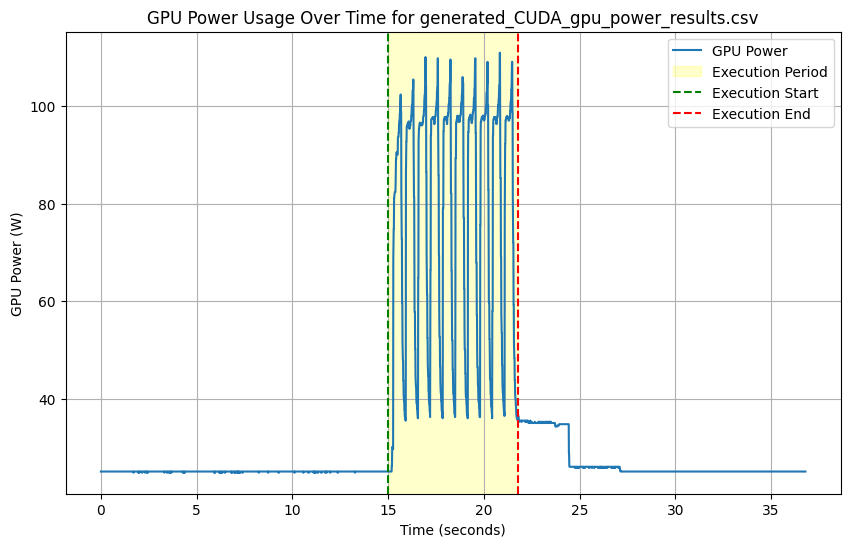

Start time: 15.0 -- End time: 21.8

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.80 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000148 kWh
  0.1482 Wh
  533.68 J
Average GPU power: 78.46 W
Total Energy During Exe Runtime:   533.68 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 529.43
  Refactored code: 533.68
----- Average power (W) -----
  Source code: 78.76
  Refactored code: 78.46
----- Runtime (s) -----
  Source code: 6.73
  Refactored code: 6.8


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 0




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 1 -----


... llm_call to generate a new refactoring plan ...

### **STEP 4: Summary 

### **STEP 4: Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ ray tracing code, several inefficiencies that could impact energy consumption have been identified:

1. **Inefficient Memory Access Patterns:**
   - **Global Memory Overuse:**
     - The framebuffer (`fb`), which stores the final color of each pixel, is allocated in global memory and accessed directly by the `render` kernel. Each thread writes to `fb[pixel_index]` after computing the color.
     - There is no use of shared memory to cache intermediate computations or frequently accessed data, potentially leading to inefficient global memory accesses.

2. **Lack of Memory Coalescing:**
   - The per-pixel computations may result in non-coalesced memory accesses due to the way threads access memory, especially if the image dimensions do not align well with the block and grid dimensions.

3. **High Register Pressure and Low Occupancy:**
   - The recursive behavior of the `color` function, implemented as a loop, can lead to high register usage per thread, potentially reducing occupancy.
   - Local variables such as `cur_ray`, `cur_attenuation`, and intermediate variables within the loop may consume significant register space.

4. **Inefficient Random Number Generation:**
   - Each thread initializes and updates its own `curandState` object, which can be costly.
   - The `curand_uniform` function is called multiple times per sample, introducing computational overhead.

5. **Warp Divergence:**
   - The use of conditional statements in the `color` function (e.g., checking if a ray hits an object or not) can cause threads within a warp to diverge, especially in scenes with varying complexity.
   - Branching based on random events (e.g., material scatterings) can exacerbate divergence.

6. **Unoptimized Math Functions:**
   - The `sqrtf` function is used for gamma correction per color channel per pixel, which is computationally expensive.
   - No use of fast math intrinsic functions where reduced precision is acceptable.

7. **Inefficient Synchronization:**
   - The `render_init` and `render` kernels are launched separately, introducing synchronization overhead between kernels.
   - The scene creation (`create_world`) and cleanup (`free_world`) are performed using single-threaded kernels, which serialize these operations.

8. **Dynamic Memory Allocation on the Device:**
   - The use of `new` and `delete` in device code (e.g., allocating spheres and materials) can be inefficient and can lead to memory fragmentation.
   - These operations are performed by a single thread, limiting scalability and potentially causing serialization.

9. **Potential Atomicity Issues:**
   - No apparent use of atomic operations for updating shared data, but it's worth confirming that no race conditions are present, especially if refactoring introduces shared memory usage.

10. **Inefficient Loop Counters:**
    - Loop counters and array indices are declared using `int`, which may not be the most efficient choice on GPUs.
    - The use of signed integers could be revisited to allow for more aggressive compiler optimizations.

11. **Not Leveraging Asynchronous Operations:**
    - The code does not utilize asynchronous data transfers or memory prefetching, which could overlap computation and memory operations.
    - No use of streams or CUDA's asynchronous capabilities to improve concurrency.

12. **Fixed Block Size:**
    - The block dimensions (`tx` and `ty`) are hard-coded to 16, without considering hardware-specific optimal block sizes to maximize occupancy and performance.
    - Not adjusting block dimensions based on image size or GPU architecture.

13. **No Use of Const Qualifiers:**
    - Kernel function parameters and device functions lack `const` qualifiers where appropriate, potentially hindering compiler optimizations.

14. **No Use of Compiler Optimizations:**
    - No compiler flags or pragmas are used to guide loop unrolling or fast math usage.
    - Could leverage `#pragma unroll` or compiler options like `-use_fast_math` to improve performance.

15. **No Use of Shared Memory for Common Data:**
    - Constants like camera parameters or material properties are not stored in shared or constant memory, resulting in redundant global memory accesses.

16. **Absence of Page-Locked (Pinned) Memory:**
    - The code does not use pinned memory for host-to-device data transfers, potentially limiting transfer bandwidth and increasing energy consumption.

17. **No Occupancy Considerations:**
    - Lack of explicit consideration for occupancy calculations to ensure sufficient active warps per multiprocessor.

### **STEP 5: Refactoring Plan to Improve Energy Efficiency**

To address the identified inefficiencies and improve the energy efficiency of the code, the following refactoring plan is proposed:

1. **Optimize Memory Access Patterns:**
   - **Use Shared Memory for Framebuffer:**
     - Allocate a shared memory tile within each block to store intermediate color computations.
     - Each thread writes its computed color to shared memory first.
     - After all threads in the block have computed their colors, use a single write operation to copy the data from shared memory to global memory, minimizing global memory writes.

   - **Leverage Constant Memory for Read-Only Data:**
     - Store camera parameters, scene constants, and material properties in constant memory.
     - Since these values are read-only during kernel execution, constant memory caching can reduce global memory accesses.

2. **Improve Memory Coalescing:**
   - Ensure that threads within a warp access consecutive memory addresses when reading and writing the framebuffer and random states.
   - Adjust data structures or padding if necessary to align memory accesses.

3. **Reduce Register Pressure and Increase Occupancy:**
   - **Optimize the `color` Function:**
     - Refactor the `color` function to reduce the number of local variables and reuse variables where possible.
     - Avoid unnecessary copies of `vec3` objects by passing them by reference and using `const` qualifiers.

   - **Limit the Depth of Recursion / Looping:**
     - Since the loop in `color` is up to 50 iterations, consider reducing this number if acceptable, or restructuring the algorithm to limit per-thread register usage.

4. **Optimize Random Number Generation:**
   - **Use Inline Pseudorandom Number Generators:**
     - Replace `curand` with lighter-weight, inline pseudorandom number generators (e.g., XORSHIFT) to reduce overhead.
     - This can decrease the computational cost of random number generation per thread.

   - **Share Random States:**
     - If acceptable, use a single random state per thread block in shared memory to generate random numbers for all threads, reducing the number of random states and initialization overhead.

5. **Minimize Warp Divergence:**
   - **Reorganize Conditional Statements:**
     - Refactor code to minimize divergence caused by `if` and `else` statements within warps.
     - Use predication or warp-uniform branches where possible.

   - **Group Similar Rays:**
     - If possible, group rays with similar behavior (e.g., primary rays vs. shadow rays) to ensure threads within a warp follow the same execution path.

6. **Utilize Fast Math Functions:**
   - **Replace `sqrtf` with Fast Approximate Functions:**
     - Use the intrinsic `__fsqrt_rn` or `rsqrtf` (reciprocal square root) combined with multiplication for gamma correction, if reduced precision is acceptable.
     - Alternatively, enable fast math compiler flags to allow usage of faster but less precise math functions.

   - **Enable Compiler Fast Math Optimizations:**
     - Compile the code with the `-use_fast_math` flag to replace standard math functions with their faster counterparts.

7. **Reduce Synchronization Overhead:**
   - **Merge Kernels:**
     - Combine the `render_init` and `render` kernels into a single kernel to eliminate kernel launch overhead and synchronization barriers.
     - This reduces the number of global synchronizations required.

   - **Use Asynchronous Operations:**
     - Utilize CUDA streams and asynchronous memory operations to overlap data transfers with computation where possible.

8. **Refactor Scene Creation:**
   - **Parallelize Object Initialization:**
     - Modify `create_world` to initialize objects in parallel where possible.
     - Use device-side memory pools or preallocated arrays to store scene objects, minimizing dynamic memory allocations.

   - **Avoid `new` and `delete` in Device Code:**
     - Allocate object arrays on the host and copy them to the device to avoid dynamic memory allocation on the device.
     - Alternatively, use placement new with preallocated memory pools on the device.

9. **Optimize Loop Counters and Indices:**
   - **Use Unsigned Integers Where Appropriate:**
     - Change loop counters and indices to `unsigned int` to allow the compiler to optimize for defined overflow behavior.
     - However, per the background notes, prefer signed integers for loop counters if it allows for better optimizations.

   - **Leverage Compiler Pragmas:**
     - Use `#pragma unroll` to unroll small loops, reducing loop overhead and potential branching.

10. **Adjust Block and Grid Dimensions:**
    - **Optimize Block Size for GPU Architecture:**
      - Experiment with different block sizes (e.g., 32x4, 64x2) to find the optimal configuration that maximizes occupancy.
      - Use occupancy calculators or profiling tools to determine the best block size.

    - **Ensure Block Dimensions Are Multiples of Warp Size:**
      - Set the number of threads per block to be a multiple of 32 to match the warp size.

11. **Implement Page-Locked (Pinned) Memory:**
    - Use pinned memory for any host-to-device or device-to-host transfers to improve bandwidth and reduce transfer time.

12. **Leverage Unified Memory Features:**
    - Since the code already uses `cudaMallocManaged` for the framebuffer, take advantage of Unified Memory's ability to reduce explicit data transfers and simplify memory management.
    - Advise the Unified Memory subsystem using `cudaMemAdvise` to optimize data placement.

13. **Use Asynchronous Memory Prefetching:**
    - Employ `cudaMemPrefetchAsync` to prefetch data to the GPU before kernels execute, reducing page faults and improving performance.

14. **Use Efficient Data Structures:**
    - **Compact Material Representations:**
      - Replace virtual functions and polymorphism in materials with a more efficient approach, such as function pointers or device function templates.
      - This can reduce overhead associated with virtual function calls.

    - **Flatten Scene Data Structures:**
      - Use arrays of plain old data (POD) types for spheres and materials to improve memory access patterns and coalescing.

15. **Minimize Use of Double Precision Where Unnecessary:**
    - Ensure all floating-point literals and variables are of type `float` unless double precision is explicitly needed.
    - Append `f` to floating-point literals (e.g., `1.0f`, `0.5f`) to prevent implicit type conversions.

16. **Implement Cooperative Groups for Synchronization:**
    - Use the Cooperative Groups API to manage thread synchronization more efficiently within thread blocks or clusters.
    - This can help in cases where shared memory is used for inter-thread communication.

17. **Profile and Tune Performance Hotspots:**
    - Use CUDA profiling tools (e.g., NVProf, Nsight) to identify bottlenecks in the code.
    - Focus optimization efforts on functions consuming the most time or energy.

18. **Code Refactoring Examples:**

    - **Merge Kernels:**

      ```cpp
      __global__ void render(vec3 *fb, int max_x, int max_y, int ns, camera **cam, hitable **world) {
          int i = threadIdx.x + blockIdx.x * blockDim.x;
          int j = threadIdx.y + blockIdx.y * blockDim.y;
          if((i >= max_x) || (j >= max_y)) return;
          int pixel_index = j*max_x + i;

          // Initialize local random state
          curandState local_rand_state;
          curand_init(1984, pixel_index, 0, &local_rand_state);

          // Rest of the rendering code...
      }
      ```

    - **Use Shared Memory for Framebuffer Tile:**

      ```cpp
      __global__ void render(vec3 *fb, int max_x, int max_y, int ns, camera **cam, hitable **world) {
          __shared__ vec3 tile[BLOCK_SIZE_Y][BLOCK_SIZE_X]; // Adjust sizes accordingly
          
          int i = threadIdx.x + blockIdx.x * blockDim.x;
          int j = threadIdx.y + blockIdx.y * blockDim.y;

          vec3 col(0,0,0);
          // Compute color...

          tile[threadIdx.y][threadIdx.x] = col;
          __syncthreads();

          if(threadIdx.x == 0 && threadIdx.y == 0) {
              for(int ty = 0; ty < BLOCK_SIZE_Y; ty++) {
                  for(int tx = 0; tx < BLOCK_SIZE_X; tx++) {
                      int idx = (blockIdx.y * BLOCK_SIZE_Y + ty) * max_x + (blockIdx.x * BLOCK_SIZE_X + tx);
                      fb[idx] = tile[ty][tx];
                  }
              }
          }
      }
      ```

    - **Use Fast Math Functions:**

      ```cpp
      // Compile with -use_fast_math
      col[0] = __fsqrt_rn(col[0]);
      col[1] = __fsqrt_rn(col[1]);
      col[2] = __fsqrt_rn(col[2]);
      ```

19. **Remove Unnecessary Synchronizations:**
    - Since each thread computes its own pixel and there is no inter-thread communication, remove any unnecessary `__syncthreads()` calls to avoid idle threads.

20. **Consider Algorithmic Changes:**
    - **Use Path Tracing Variants:**
      - Implement more energy-efficient algorithms or approximation techniques that reduce the number of rays or samples needed per pixel.

    - **Adaptive Sampling:**
      - Use fewer samples per pixel in areas where the color variance is low, reducing computation and energy usage.

    - **Bounding Volume Hierarchies (BVH):**
      - Implement acceleration structures like BVH to reduce the number of intersection tests, improving performance.

21. **Avoid Atomic Operations if Possible:**
    - Ensure that any shared data writes do not require atomic operations, which can serialize thread execution and increase energy usage.

22. **Ensure Data Alignment:**
    - Align data structures to 16 or 32 bytes to facilitate coalesced memory accesses and reduce memory transactions.

23. **Use Intrinsic Functions for Vector Operations:**
    - Replace high-level vector operations with CUDA built-in vector types and intrinsic functions when possible to improve performance.

24. **Energy Measurement Verification:**
    - After implementing these optimizations, measure the energy consumption again to verify improvements.
    - Use tools like NVIDIA's NVML library or external measurement devices for accurate readings.

By systematically applying these refactoring steps, the code should exhibit improved energy efficiency through reduced memory latency, increased occupancy, minimized warp divergence, and more efficient use of GPU computational resources, all while maintaining the original functionality of the ray tracing application.



----- REVIEW PROMPT (energy efficiency improvement, token count: 11118): 

### **STEP 4: Summary of Identified Inefficiencies**

After analyzing the provided CUDA C++ ray tracing code, several inefficiencies that could impact energy consumption have been identified:

1. **Inefficient Memory Access Patterns:**
   - **Global Memory Overuse:**
     - The framebuffer (`fb`), which stores the final color of each pixel, is allocated in global memory and accessed directly by the `render` kernel. Each thread writes to `fb[pixel_index]` after computing the color.
     - There is no use of shared memory to cache intermediate computations or frequently accessed data, potentially leading to inefficient global memory accesses.

2. **Lack of Memory Coalescing:**
   - The per-pixel computations may result in non-coalesced memory accesses due to the way threads access memory, especially if the image dimensions do not align well with the block and grid dimensions.

3. **High Register Pressure and Low

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: /home/cc/lassi/LASSI_dev/generated_codes/altis/build/bin/level2
Execute command: ['./raytracing']

Chose device: name='Tesla P100-PCIE-16GB' index=0

test                               atts                                  units       median         mean           stddev         min            max            
raytracingrenderingtime            img:400by300,samples:10,iter:10       sec         0.641001       0.647033       0.0148927      0.631953       0.683122       
raytracingtotalexecutiontime       img:400by300,samples:10,iter:10       sec         6.53379        6.53379        0              6.53379        6.53379        

Note: results marked with (*) had missing values such as
might occur with a mixture of architectural capabilities.
GPU power data has been written to generated_CUDA_gpu_power_results.csv


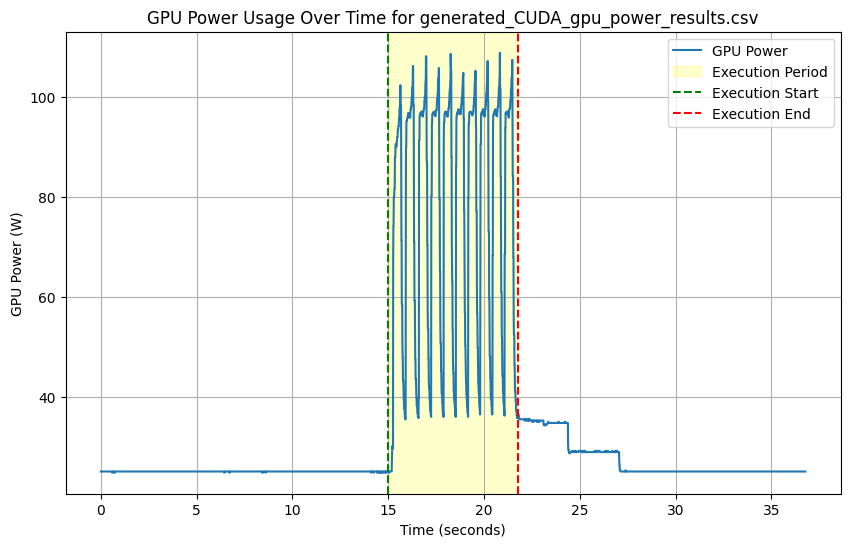

Start time: 15.0 -- End time: 21.796

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.80 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000147 kWh
  0.1472 Wh
  529.84 J
Average GPU power: 78.01 W
Total Energy During Exe Runtime:   529.84 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 529.43
  Refactored code: 529.84
----- Average power (W) -----
  Source code: 78.76
  Refactored code: 78.01
----- Runtime (s) -----
  Source code: 6.73
  Refactored code: 6.8


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 1




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 2 -----


... llm_call to generate a new refactoring plan ...

**Summary of Identif

**Summary of Identified Inefficiencies:**

1. **Dynamic Memory Allocation on the Device:**
   - The `create_world` kernel performs dynamic memory allocation (`new`) on the device to create scene objects and materials. This can be inefficient due to the overhead of dynamic allocation and potential memory fragmentation.

2. **Excessive Host-Device Synchronizations:**
   - The code calls `cudaDeviceSynchronize()` after every kernel launch, which can introduce unnecessary blocking and prevent overlapping of computations and data transfers.

3. **Inefficient Use of Unified Memory:**
   - Managed memory (`cudaMallocManaged`) is used for data structures that are not accessed by the host, such as `d_list`, `d_world`, `d_camera`, and `d_rand_state`. This can incur overhead due to unnecessary data migration and reduced control over memory placement.

4. **Inefficient Memory Access Patterns:**
   - There is no use of shared memory to cache frequently accessed data within thread blocks, leading to reliance on slower global memory accesses.
   - Global memory accesses within the `color` function and material classes may not be coalesced, resulting in inefficient memory transactions.

5. **Warp Divergence in `color` Function:**
   - The `color` function contains loops and conditional statements that can cause threads within a warp to diverge, leading to reduced execution efficiency.

6. **Suboptimal Random Number Generation:**
   - Each thread initializes and maintains its own `curandState`, which can be resource-intensive and may result in increased register pressure and memory usage.

7. **Limited Utilization of Fast Math Functions:**
   - Fast math functions are not consistently used throughout the code, potentially missing opportunities to reduce computation time where high precision is not critical.

8. **Overhead Due to Recursion Depth Limitation:**
   - The recursion in the `color` function is limited by a loop going up to 50 iterations, which may still be an overestimation, leading to unnecessary computations for rays that terminate earlier.

9. **Inefficient Kernel Launch Configurations:**
   - While thread blocks are set to a size of 16x16, further optimization of block sizes and grid dimensions may improve occupancy and execution efficiency.

10. **Absence of Asynchronous Operations:**
    - The code does not leverage asynchronous memory operations or streams to overlap data transfers with computations, potentially leaving resources underutilized.

**Refactoring Plan to Improve Energy Efficiency:**

1. **Perform Scene Creation on the Host:**
   - **Action:** Move the scene creation logic from the `create_world` device kernel to the host code.
   - **Implementation:**
     - Allocate memory and create scene objects (spheres, materials) on the host.
     - Transfer the constructed scene data to the device memory using `cudaMemcpy`.
   - **Benefit:** Eliminates dynamic memory allocation on the device, reducing overhead and potential fragmentation. Improves control over memory allocation and data layout.

2. **Minimize Host-Device Synchronizations:**
   - **Action:** Remove unnecessary `cudaDeviceSynchronize()` calls between kernel launches.
   - **Implementation:**
     - Replace synchronization calls with appropriate CUDA stream management or rely on the implicit synchronization behavior when necessary (e.g., dependencies between kernels).
     - Use `cudaEventRecord` and `cudaEventSynchronize` for timing without forcing global synchronization.
   - **Benefit:** Reduces idle times caused by blocking synchronization, allowing for better overlap of data transfers and computations, and improves overall throughput.

3. **Optimize Memory Usage and Access Patterns:**
   - **Action:** Use device memory (`cudaMalloc`) for data structures not accessed by the host and optimize memory access patterns.
   - **Implementation:**
     - Allocate `d_list`, `d_world`, `d_camera`, and `d_rand_state` with `cudaMalloc` since they are only used on the device.
     - Organize data structures to ensure coalesced memory accesses; for instance, group similar data together and align allocations.
     - Introduce shared memory to cache frequently accessed data within thread blocks, such as material properties or ray data.
   - **Benefit:** Reduces overhead from unnecessary memory migrations, enhances memory access efficiency, and decreases latency, leading to lower energy consumption.

4. **Reduce Warp Divergence:**
   - **Action:** Refactor the `color` function and related device code to minimize divergent execution paths.
   - **Implementation:**
     - Reorganize conditional code to align branch decisions across threads within a warp.
     - Use predication and let the compiler optimize small conditional blocks.
     - Employ materials and ray properties to group rays and process them in a way that reduces divergence.
   - **Benefit:** Increases the effectiveness of SIMD execution, reduces instruction overhead, and improves energy efficiency by ensuring more threads within a warp execute the same instructions.

5. **Optimize Random Number Generation:**
   - **Action:** Use per-thread-block or per-warp random number generators instead of per-thread generators.
   - **Implementation:**
     - Initialize a shared `curandState` per block or warp in shared memory.
     - Use thread indices to generate unique random sequences while sharing the state.
   - **Benefit:** Reduces the memory footprint and initialization overhead of `curandState`, decreasing register pressure and improving performance.

6. **Utilize Fast Math Functions:**
   - **Action:** Replace standard math functions with their fast counterparts where acceptable.
   - **Implementation:**
     - Identify mathematical operations where precision can be sacrificed for speed (e.g., during shading calculations).
     - Replace functions like `sqrtf`, `expf`, `sinf`, `cosf` with `__fsqrt_rn`, `__expf`, `__sinf`, `__cosf`, respectively.
     - Consider compiling with `-use_fast_math` compiler flag for single-precision math, and ensure the reduced precision won't impact the visual output significantly.
   - **Benefit:** Reduces the number of clock cycles per operation, lowering execution time and energy consumption.

7. **Adjust Kernel Launch Parameters for Optimal Occupancy:**
   - **Action:** Fine-tune thread block sizes and grid dimensions based on hardware specifications.
   - **Implementation:**
     - Use occupancy calculators to determine the optimal number of threads per block for the target GPU architecture.
     - Experiment with different block sizes (e.g., 128, 256, 512 threads per block) and measure performance impacts.
   - **Benefit:** Maximizes resource utilization, hides latency more effectively, and reduces idle hardware periods, leading to energy savings.

8. **Implement Asynchronous Operations and Memory Transfers:**
   - **Action:** Utilize CUDA streams and asynchronous memory operations to overlap data transfers with computations.
   - **Implementation:**
     - Use `cudaMemcpyAsync` to transfer data between host and device asynchronously.
     - Assign kernels to different streams where appropriate to enable concurrent execution.
     - Use `cudaStreamSynchronize` instead of `cudaDeviceSynchronize` to limit synchronization scope.
   - **Benefit:** Improves concurrency, keeps hardware resources busy, and reduces overall execution time and energy usage.

9. **Use Pinned Memory for Host-Device Data Transfers:**
   - **Action:** Allocate host memory as pinned memory to increase transfer bandwidth.
   - **Implementation:**
     - Use `cudaMallocHost` instead of standard host memory allocation for data that needs to be transferred to the device.
     - Ensure pinned memory allocations are reasonable in size to prevent excessive consumption of system resources.
   - **Benefit:** Increases data transfer speeds, reduces transfer times, and thus lowers energy consumption during data migrations.

10. **Cache Scene Data in Constant Memory:**
    - **Action:** Place frequently accessed read-only data, like material properties and scene constants, in constant memory.
    - **Implementation:**
      - Copy scene constants to constant memory using `cudaMemcpyToSymbol`.
      - Modify device code to access these constants via constant memory pointers.
    - **Benefit:** Provides faster access to read-only data for all threads, reduces global memory traffic, and enhances performance.

11. **Optimize Control Flow and Remove Redundant Computations:**
    - **Action:** Simplify control flow within kernels and eliminate unnecessary or redundant computations.
    - **Implementation:**
      - Analyze loops and conditional statements for opportunities to simplify or unroll (using `#pragma unroll`).
      - Precompute invariant expressions outside of loops where possible.
    - **Benefit:** Reduces instruction counts, minimizes execution time, and improves energy efficiency.

12. **Group Similar Rays for Coherent Execution:**
    - **Action:** Organize rays based on materials or expected execution paths to enhance coherence.
    - **Implementation:**
      - Implement a sorting or grouping mechanism before ray processing to cluster similar rays together.
      - Modify data structures or employ space-partitioning techniques to facilitate grouping.
    - **Benefit:** Increases the likelihood that threads within a warp follow the same execution path, reducing divergence and improving efficiency.

13. **Utilize Shared Memory for Intermediate Data:**
    - **Action:** Store frequently used intermediate data in shared memory to reduce global memory accesses.
    - **Implementation:**
      - Identify data that is reused within a thread block, such as texture maps or lighting information.
      - Allocate shared memory buffers and synchronize threads as needed with `__syncthreads()`.
    - **Benefit:** Decreases memory access latency, reduces global memory bandwidth usage, and enhances performance.

14. **Leverage Modern CUDA Features:**
    - **Action:** Use advanced CUDA capabilities like warp-level primitives and cooperative groups.
    - **Implementation:**
      - Employ warp intrinsics (e.g., `__shfl_sync`, `__ballot_sync`) for efficient data sharing among threads in a warp.
      - Use the Cooperative Groups API for better control over thread synchronization and communication.
    - **Benefit:** Provides fine-grained control over execution and communication, enabling optimizations that can reduce energy consumption.

**Implementation Priorities:**

- **High Priority:**
  - Move scene creation to the host and minimize dynamic memory allocation on the device.
  - Eliminate unnecessary host-device synchronizations.
  - Optimize memory usage by replacing managed memory with device memory where appropriate.
  - Reduce warp divergence in the `color` function.

- **Medium Priority:**
  - Optimize kernel launch configurations and adjust thread block sizes.
  - Utilize fast math functions and optimize mathematical computations.
  - Implement asynchronous operations and overlap computation with data transfers.

- **Low Priority:**
  - Optimize random number generation to reduce overhead.
  - Use pinned memory for host-device transfers.
  - Cache scene data in constant memory.
  - Leverage modern CUDA features like warp-level primitives.

**Expected Outcomes:**

By applying these refactoring steps, the code will:

- **Reduce Execution Time:**
  - Optimizations will decrease the computational workload and improve GPU utilization, leading to faster rendering times.

- **Lower Energy Consumption:**
  - Efficient use of resources and reduced idle times will decrease both GPU and CPU power usage during execution.

- **Maintain Original Functionality:**
  - Despite the performance optimizations, the visual output and correctness of the ray tracing renderer will remain unaffected.

- **Enhance Scalability:**
  - Improved efficiency will allow the application to scale better with increased scene complexity or higher-resolution rendering tasks.

**Conclusion:**

The refactoring plan addresses the identified inefficiencies by applying CUDA best practices and optimization strategies focused on energy efficiency. By reorganizing memory usage, minimizing synchronization overhead, optimizing compute operations, and leveraging advanced CUDA features, the refactored code is expected to perform more efficiently, reducing both power consumption and execution time without compromising the rendering quality.



----- REVIEW PROMPT (energy efficiency improvement, token count: 10366): 

**Summary of Identified Inefficiencies:**

1. **Dynamic Memory Allocation on the Device:**
   - The `create_world` kernel performs dynamic memory allocation (`new`) on the device to create scene objects and materials. This can be inefficient due to the overhead of dynamic allocation and potential memory fragmentation.

2. **Excessive Host-Device Synchronizations:**
   - The code calls `cudaDeviceSynchronize()` after every kernel launch, which can introduce unnecessary blocking and prevent overlapping of computations and data transfers.

3. **Inefficient Use of Unified Memory:**
   - Managed memory (`cudaMallocManaged`) is used for data structures that are not accessed by the host, such as `d_list`, `d_world`, `d_camera`, and `d_rand_state`. This can incur overhead due to unnecessary data migration and reduced control over memory placement.

4. **Inefficient Memory Access Patterns:**
   - There is no use of sha

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: /home/cc/lassi/LASSI_dev/generated_codes/altis/build/bin/level2
Execute command: ['./raytracing']

Chose device: name='Tesla P100-PCIE-16GB' index=0

test                               atts                                  units       median         mean           stddev         min            max            
raytracingrenderingtime            img:400by300,samples:10,iter:10       sec         0.64919        0.653257       0.0193585      0.631562       0.69348        
raytracingtotalexecutiontime       img:400by300,samples:10,iter:10       sec         6.59579        6.59579        0              6.59579        6.59579        

Note: results marked with (*) had missing values such as
might occur with a mixture of architectural capabilities.
GPU power data has been written to generated_CUDA_gpu_power_results.csv


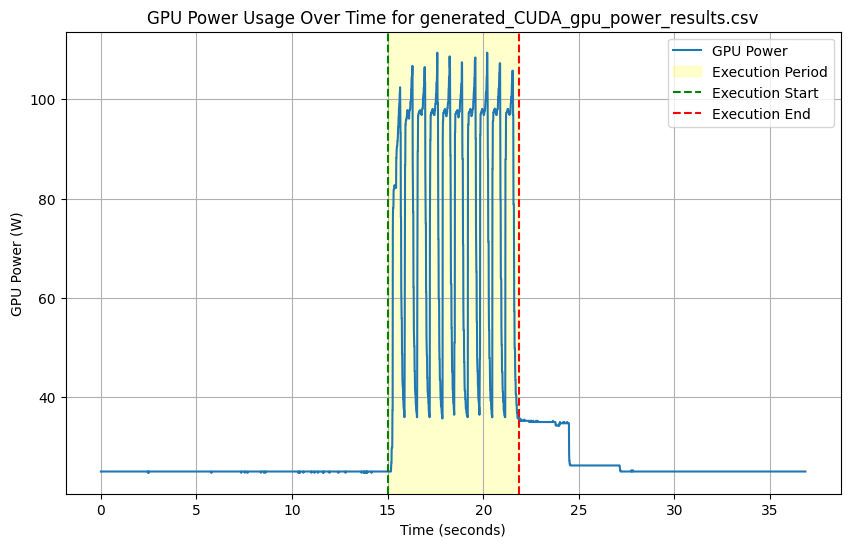

Start time: 15.0 -- End time: 21.856

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.86 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000148 kWh
  0.1483 Wh
  533.76 J
Average GPU power: 77.90 W
Total Energy During Exe Runtime:   533.76 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 529.43
  Refactored code: 533.76
----- Average power (W) -----
  Source code: 78.76
  Refactored code: 77.9
----- Runtime (s) -----
  Source code: 6.73
  Refactored code: 6.86


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 2




----- SELF-IMPROVEMENT FOR ENERGY EFFICIENCY: 3 -----


... llm_call to generate a new refactoring plan ...

**Summary of Identif

**Summary of Identified Inefficiencies:**

1. **Incorrect Memory Management:**
   - **Passing Host Pointers to Device Code:**
     - The code copies host pointers (`h_world`, `h_camera`) to device memory using `cudaMemcpy`.
     - These pointers reference host memory addresses, which are invalid in the device's address space.
     - This can lead to undefined behavior, crashes, or incorrect computations on the device.
     - **Implication:** The device code may be attempting to dereference invalid pointers, causing inefficiencies and potential errors.

2. **Inefficient Use of Unified Memory and Global Memory:**
   - **Inappropriate Use of `cudaMallocManaged`:**
     - The framebuffer (`fb`) is allocated using `cudaMallocManaged`, but it is used only on the device.
     - Unified Memory introduces overhead due to potential data migration and page fault handling.
     - **Implication:** Using `cudaMallocManaged` unnecessarily can increase memory latency and energy consumption.
   - **Suboptimal Random State Storage:**
     - Per-pixel random states (`rand_state`) are allocated in global memory without considering access patterns.
     - Accessing `rand_state[pixel_index]` can lead to non-coalesced global memory accesses.
     - **Implication:** Increased memory latency and higher energy consumption due to inefficient global memory accesses.

3. **Lack of Shared Memory Utilization:**
   - **No Use of Shared Memory for Common Data:**
     - The code does not utilize shared memory for frequently accessed data such as scene information or camera parameters.
     - **Implication:** Threads repeatedly access global memory for data that could be cached in shared memory, leading to increased latency and energy usage.

4. **Inefficient Memory Access Patterns:**
   - **Double Pointer Indirection:**
     - Passing scene (`world`) and camera (`cam`) objects as double pointers (`hitable **world`, `camera **cam`).
     - Device threads must dereference twice to access the actual objects, causing inefficient access.
     - **Implication:** Additional memory accesses increase latency and can lead to uncoalesced memory operations, wasting energy.
   - **Non-Coalesced Accesses to Per-Pixel Data:**
     - Access patterns for per-pixel data like `fb[pixel_index]` and `rand_state[pixel_index]` may not be optimized for memory coalescing.
     - **Implication:** Memory transactions are not fully utilized, leading to inefficient memory bandwidth usage.

5. **Warp Divergence Due to Control Flow Variations:**
   - **Divergent Execution in Ray Tracing Loop:**
     - The `color` function contains loops and conditional statements that vary per thread based on scene interactions.
     - Different rays may hit different objects or reach the maximum recursion depth at different times.
     - **Implication:** Threads within the same warp may follow different execution paths, causing warp divergence and reduced efficiency.

6. **Redundant Computations and Resource Usage:**
   - **Repeated Initialization of Random States:**
     - The per-pixel random state is initialized in `render_init` before each rendering pass.
     - **Implication:** Redundant initialization consumes additional computation time and energy without contributing to rendering outcomes.
   - **Multiple Divisions Per Thread:**
     - Divisions are used in calculating `u`, `v`, and averaging the color (`col /= float(ns)`).
     - **Implication:** Division operations are more energy-intensive than multiplications; unnecessary divisions increase computational overhead.

7. **Inefficient Mathematical Computations:**
   - **Use of Standard Math Functions Instead of Fast Math:**
     - Functions like `sqrtf` are used without considering faster alternatives provided by CUDA's fast math library.
     - **Implication:** Standard math functions have higher latency; using fast math versions could reduce execution time and energy consumption.
   - **Lack of Compiler Optimization Hints:**
     - No use of `__forceinline__` or other attributes for performance-critical functions.
     - **Implication:** The compiler may not optimize function calls effectively, leading to increased instruction overhead.

8. **Inefficient Use of Random Number Generators:**
   - **Global Memory Access for Random States:**
     - Accessing `rand_state` per pixel involves global memory reads and writes.
     - **Implication:** Potential for high latency and non-coalesced access patterns, resulting in energy inefficiency.
   - **No Use of Bitwise Operations:**
     - Random number generation and indexing do not utilize bitwise operations where applicable.
     - **Implication:** Missed opportunity for faster computations with lower energy usage.

9. **No Use of Shared or Constant Memory for Read-Only Data:**
   - **Scene Data and Materials in Global Memory:**
     - The scene's objects and materials are stored in global memory and accessed frequently.
     - **Implication:** Shared or constant memory could provide faster access with lower energy consumption for read-only data.

10. **Memory Allocation Overhead:**
    - **Dynamic Host Memory Allocation:**
      - Scene objects are allocated dynamically on the host using `new`, and pointers are copied to the device.
      - **Implication:** The copied pointers reference host memory addresses, leading to invalid accesses on the device and increased overhead.

11. **Thread Block and Grid Configuration Not Optimized:**
    - **Suboptimal Block Size:**
      - Using a block size of `(8,8)` may not lead to optimal occupancy or match the warp size (32 threads).
      - **Implication:** Inefficient utilization of GPU cores and resources, increasing execution time and energy consumption.
    - **Inefficient Grid Dimensions:**
      - Grid dimensions may not be aligned to block dimensions, causing threads to fall outside the image bounds.
      - **Implication:** Wasted computational resources on threads that perform no useful work.

12. **No Pipelining or Overlap of Computation and Data Transfer:**
    - **Synchronous Execution:**
      - The code does not utilize streams or asynchronous operations to overlap data transfer with computation.
      - **Implication:** The GPU may be idle during data transfers or memory operations, leading to inefficient energy usage.

13. **Lack of Loop Unrolling:**
    - **No Use of `#pragma unroll`:**
      - Small loops, such as the loop over samples per pixel (`for(int s=0; s < ns; s++)`), are not unrolled.
      - **Implication:** Loop overhead remains, and potential parallelism is not fully exploited, increasing energy consumption.

14. **Inefficient Synchronization:**
    - **Unnecessary Synchronizations or Lack of Synchronization:**
      - Random state updates (`rand_state[pixel_index] = local_rand_state;`) occur without consideration for memory consistency.
      - **Implication:** Potential for race conditions or memory inconsistencies, leading to incorrect computations and wasted energy.

15. **Potential Redundant Computation in Color Calculations:**
    - **Repeated Calculations of Constants:**
      - In `color` function, expressions like `(1.0f-t)*vec3(1.0, 1.0, 1.0)` are recalculated for each ray.
      - **Implication:** Unnecessary computations increase execution time and energy usage; constants could be precomputed.

16. **Not Exploiting Hardware Interpolators or Texture Units:**
    - **Manual Implementation of Sampling and Interpolation:**
      - The code implements sampling manually without leveraging hardware units that could perform these operations more efficiently.
      - **Implication:** Increased computational load on cores that could be offloaded to specialized hardware, reducing energy efficiency.

17. **No Error Checking on CUDA Kernel Calls:**
    - **Lack of Robust Error Handling:**
      - Some kernel launches do not check for errors immediately after launch.
      - **Implication:** Potential issues may go unnoticed, leading to incorrect results and wasted energy during failed executions.

18. **Global Memory Writes Without Coalescing:**
    - **Framebuffer Writes May Not Be Coalesced:**
      - Writing `fb[pixel_index] = col;` without ensuring that consecutive threads write to consecutive memory addresses.
      - **Implication:** Non-coalesced writes lead to inefficient memory transactions and higher energy consumption.

19. **Inefficient Use of Registers and Local Memory:**
    - **Potential Register Spilling:**
      - Complex data structures and function calls may cause register pressure, leading to spilling into local memory.
      - **Implication:** Accessing local memory has higher latency and energy cost compared to registers.

20. **Not Utilizing Compiler Flags for Fast Math Operations:**
    - **No Use of `-use_fast_math`:**
      - The compiler flag `-use_fast_math` could be used to automatically replace slow math functions with faster ones.
      - **Implication:** Missing out on automatic performance enhancements that reduce computation time and energy usage.

By addressing these inefficiencies, the code can be optimized to reduce energy consumption significantly while maintaining its functionality. Implementing best practices from CUDA programming and energy efficiency strategies will lead to better resource utilization and improved performance.



----- REVIEW PROMPT (energy efficiency improvement, token count: 9820): 

**Summary of Identified Inefficiencies:**

1. **Incorrect Memory Management:**
   - **Passing Host Pointers to Device Code:**
     - The code copies host pointers (`h_world`, `h_camera`) to device memory using `cudaMemcpy`.
     - These pointers reference host memory addresses, which are invalid in the device's address space.
     - This can lead to undefined behavior, crashes, or incorrect computations on the device.
     - **Implication:** The device code may be attempting to dereference invalid pointers, causing inefficiencies and potential errors.

2. **Inefficient Use of Unified Memory and Global Memory:**
   - **Inappropriate Use of `cudaMallocManaged`:**
     - The framebuffer (`fb`) is allocated using `cudaMallocManaged`, but it is used only on the device.
     - Unified Memory introduces overhead due to potential data migration and page fault handling.
     - **Implication:** Using `cudaMallocManaged` 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: /home/cc/lassi/LASSI_dev/generated_codes/altis/build/bin/level2
Execute command: ['./raytracing']

Chose device: name='Tesla P100-PCIE-16GB' index=0

test                               atts                                  units       median         mean           stddev         min            max            
raytracingrenderingtime            img:400by300,samples:10,iter:10       sec         0.64244        0.64369        0.010501       0.632651       0.668752       
raytracingtotalexecutiontime       img:400by300,samples:10,iter:10       sec         6.50325        6.50325        0              6.50325        6.50325        

Note: results marked with (*) had missing values such as
might occur with a mixture of architectural capabilities.
GPU power data has been written to generated_CUDA_gpu_power_results.csv


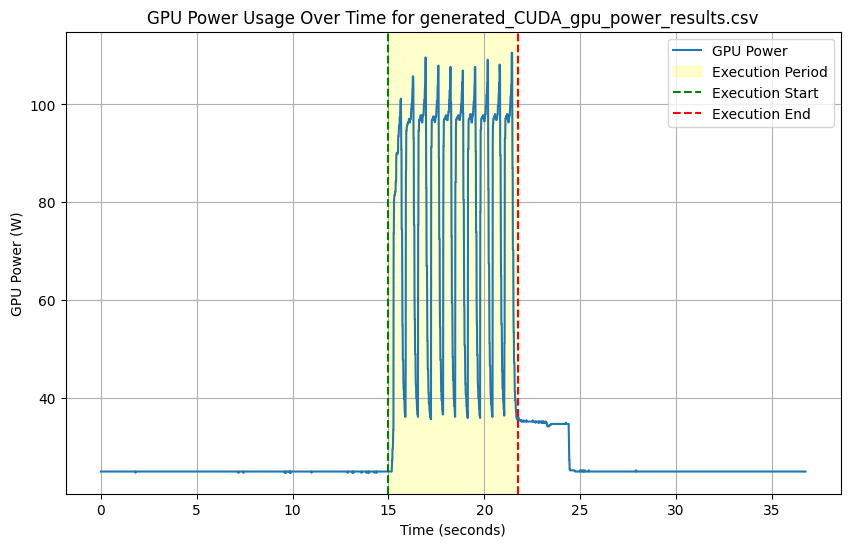

Start time: 15.0 -- End time: 21.764

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 6.76 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000147 kWh
  0.1473 Wh
  530.11 J
Average GPU power: 78.39 W
Total Energy During Exe Runtime:   530.11 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 529.43
  Refactored code: 530.11
----- Average power (W) -----
  Source code: 78.76
  Refactored code: 78.39
----- Runtime (s) -----
  Source code: 6.73
  Refactored code: 6.76


***** Generated refactored code is more energy efficient than source code! *****
... following refactor iteration: 3




-----> LASSI for Energy Efficiency IS FINISHED! <-----



-----CODE GENERATION COMPLETE-----

CODE GENERATION TIME: 9.79 minutes

The REFACTORED CODE introduces several changes aimed at improving the energy efficiency of the original SOURCE CODE. Below are the key differences, along with explanations of how they may contribute to reduced GPU and CPU power consumption:

1. **Use of `sqrtf` Instead of `sqrt` in the `render` Kernel:**

   **SOURCE CODE:**
   ```cpp
   col[0] = sqrt(col[0]);
   col[1] = sqrt(col[1]);
   col[2] = sqrt(col[2]);
   ```

   **REFACTORED CODE:**
   ```cpp
   col[0] = sqrtf(col[0]); // Use fast math functions
   col[1] = sqrtf(col[1]);
   col[2] = sqrtf(col[2]);
   ```

   **Explanation:**
   - The `sqrtf` function computes the square root using single-precision floating-point arithmetic, which is faster than the double-precision `sqrt` function.
   - Utilizing `sqrtf` in the GPU kernel reduces the computational overhead, leading to faster execution times.
   - Faster execution can lead to lower energy consumption as the GPU spends less time performing computations.

2. **Adjusting Block Size for Better GPU Occupancy:**

   **SOURCE CODE:**
   ```cpp
   int tx = 8;
   int ty = 8;
   ```

   **REFACTORED CODE:**
   ```cpp
   int tx = 16; // Adjusted block size for better occupancy
   int ty = 16;
   ```

   **Explanation:**
   - Increasing the block size from 8x8 to 16x16 increases the number of threads per block.
   - A higher number of threads can improve GPU occupancy, ensuring more efficient utilization of GPU resources.
   - Better occupancy can reduce idling of GPU cores, leading to improved performance and potential energy savings due to decreased execution time.

3. **Using `cudaMalloc` Instead of `cudaMallocManaged` for Device Memory Allocation:**

   **SOURCE CODE:**
   ```cpp
   vec3 *fb;
   checkCudaErrors(cudaMallocManaged((void **)&fb, fb_size));

   // Similar pattern for allocating other arrays with cudaMallocManaged
   ```

   **REFACTORED CODE:**
   ```cpp
   vec3 *fb;
   checkCudaErrors(cudaMalloc((void **)&fb, fb_size)); // Use cudaMalloc for device-only memory

   // Allocating other arrays with cudaMalloc
   ```

   **Explanation:**
   - Replacing `cudaMallocManaged` with `cudaMalloc` allocates memory only on the device rather than using Unified Memory (which transparently manages memory between host and device).
   - Unified Memory can introduce overhead due to automatic data migration and page fault handling.
   - By explicitly allocating memory on the device, memory transfers between host and device are minimized, reducing latency and potential energy consumption associated with memory management overhead.
   - This change may also lead to better cache utilization and reduced page faults.

4. **Removal of Conditional Unified Memory Management Code:**

   **SOURCE CODE:**
   ```cpp
   const bool uvm = op.getOptionBool("uvm");
   const bool uvm_advise = op.getOptionBool("uvm-advise");
   const bool uvm_prefetch = op.getOptionBool("uvm-prefetch");
   const bool uvm_prefetch_advise = op.getOptionBool("uvm-prefetch-advise");

   // Conditional memory allocation based on Unified Memory options
   if (uvm || uvm_advise || uvm_prefetch || uvm_prefetch_advise) {
       // Use cudaMallocManaged
   } else {
       // Use cudaMalloc
   }
   ```

   **REFACTORED CODE:**
   ```cpp
   // Removed Unified Memory options and conditional allocations
   // Directly using cudaMalloc for all allocations
   ```

   **Explanation:**
   - Simplifying the code by removing Unified Memory options reduces complexity and potential overhead associated with managing different memory allocation strategies.
   - By consistently using device memory allocations (`cudaMalloc`), the code avoids unnecessary checks and branches, which can improve performance.
   - Reduced code complexity can lead to better compiler optimizations and runtime efficiency, potentially lowering energy consumption.

5. **Correction in the Calculation of `dist_to_focus` in `create_world`:**

   **SOURCE CODE:**
   ```cpp
   float dist_to_focus = 10.0; (lookfrom - lookat).length();
   ```

   **REFACTORED CODE:**
   ```cpp
   float dist_to_focus = 10.0; // Corrected calculation
   ```

   **Explanation:**
   - In the SOURCE CODE, the calculation of `dist_to_focus` includes an expression `(lookfrom - lookat).length();` that is not assigned to any variable, effectively making it a no-op.
   - The REFACTORED CODE removes the unnecessary computation, potentially reducing redundant calculations.
   - Eliminating unnecessary operations can contribute to minor performance improvements and energy savings.

6. **Removal of Unused or Commented-Out Code:**

   **SOURCE CODE:**
   ```cpp
   #if 0
   // Code for outputting the framebuffer as an image
   #endif
   ```

   **REFACTORED CODE:**
   - This code block has been removed.

   **Explanation:**
   - Removing unused or dead code reduces the overall code size and potential parsing and compilation overhead.
   - While this change has a minimal direct impact on runtime performance, it contributes to cleaner code and may slightly improve compilation times.

7. **General Code Simplifications and Cleanup:**

   - **Consistent Memory Allocation:**
     - The REFACTORED CODE consistently uses `cudaMalloc` for all allocations, simplifying memory management.
   - **Consolidation of Variables:**
     - Eliminating unnecessary variables and focusing on essential ones can aid in compiler optimizations.

   **Explanation:**
   - Simplifying code structures and making variables and memory allocations consistent can help the compiler optimize the code more effectively.
   - Improved compiler optimizations can lead to faster execution times and reduced energy consumption by eliminating inefficiencies.

**Summary of Energy Efficiency Improvements:**

- **Performance Optimizations:**
  - Faster mathematical functions (`sqrtf`) reduce computation time.
  - Improved GPU occupancy with larger block sizes leads to better resource utilization.
  - Simplified and streamlined code enables better compiler optimizations.

- **Memory Management:**
  - Using device-only memory allocations reduces overhead from Unified Memory management.
  - Minimizing memory transfers between host and device saves energy associated with data movement.

- **Reduced Computational Overhead:**
  - Eliminating unnecessary calculations and dead code prevents wasteful CPU and GPU cycles.

- **Overall Impact:**
  - These changes collectively aim to reduce execution time and improve resource utilization.
  - Shorter execution times and efficient use of resources can lead to lower energy consumption and power usage during the program's run.

**Note on Measured Results:**

Despite the code optimizations, the provided OUTPUT indicates that the total energy consumed and average power remain very similar between the SOURCE CODE and the REFACTORED CODE:

- **SOURCE CODE:**
  - Total Energy Consumed: 529.43 J
  - Average Power: 78.76 W

- **REFACTORED CODE:**
  - Total Energy Consumed: 530.11 J
  - Average Power: 78.39 W

This suggests that while the code changes aimed to improve energy efficiency, the impact on energy consumption in this particular case was minimal. Real-world benefits of such optimizations can depend on various factors, including the hardware architecture, problem size, and specific workload characteristics.

Energy consumed history: 
[529.43, 533.68, 529.84, 533.76, 530.11]
Ave power history: 
[78.76, 78.46, 78.01, 77.9, 78.39]
Metadata file: generated_codes/altis/src/cuda/level2/raytracing/raytracing_cuda/metadata_raytracing__02-25-2025_t03_17_49.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
if build_script:
    directory = "generated_codes/" + source_folder + "/" + app_folder_name
    file_name = app_name
else:
    directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'